In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
crops = pd.read_csv("../data/raw/crop_production_original.csv")

print("Shape:", crops.shape)
print("\nColumns:")
print(crops.columns.tolist())

display(crops.head())

crops.info()

print("\nMissing values:")
print(crops.isnull().sum())

Shape: (345407, 10)

Columns:
['State', 'District', 'Crop', 'Year', 'Season', 'Area', 'Area Units', 'Production', 'Production Units', 'Yield']


,State,District,Crop,Year,Season,Area,Area Units,Production,Production Units,Yield
0,Andaman and Nicobar Islands,NICOBARS,Arecanut,2001-02,Kharif,1254.0,Hectare,2061.0,Tonnes,1.643541
1,Andaman and Nicobar Islands,NICOBARS,Arecanut,2002-03,Whole Year,1258.0,Hectare,2083.0,Tonnes,1.655803
2,Andaman and Nicobar Islands,NICOBARS,Arecanut,2003-04,Whole Year,1261.0,Hectare,1525.0,Tonnes,1.209358
3,Andaman and Nicobar Islands,NORTH AND MIDDLE ANDAMAN,Arecanut,2001-02,Kharif,3100.0,Hectare,5239.0,Tonnes,1.690000
4,Andaman and Nicobar Islands,SOUTH ANDAMANS,Arecanut,2002-03,Whole Year,3105.0,Hectare,5267.0,Tonnes,1.696296


<class 'pandas.DataFrame'>
RangeIndex: 345407 entries, 0 to 345406
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   State             345407 non-null  str    
 1   District          345407 non-null  str    
 2   Crop              345375 non-null  str    
 3   Year              345407 non-null  str    
 4   Season            345406 non-null  str    
 5   Area              345374 non-null  float64
 6   Area Units        345407 non-null  str    
 7   Production        340414 non-null  float64
 8   Production Units  345407 non-null  str    
 9   Yield             345374 non-null  float64
dtypes: float64(3), str(7)
memory usage: 26.4 MB

Missing values:
State                  0
District               0
Crop                  32
Year                   0
Season                 1
Area                  33
Area Units             0
Production          4993
Production Units       0
Yield                 33
dtype: i

In [4]:
# 1. Missing values: count and percentage

missing_summary = pd.DataFrame({
    "Missing_Count": crops.isnull().sum(),
    "Missing_Percentage": (
        crops.isnull().sum() / len(crops) * 100
    ).round(2)
})

display(
    missing_summary.sort_values(
        "Missing_Count",
        ascending=False
    )
)

,Missing_Count,Missing_Percentage
Production,4993,1.45
Area,33,0.01
Yield,33,0.01
Crop,32,0.01
Season,1,0.00
State,0,0.00
District,0,0.00
Year,0,0.00
Area Units,0,0.00
Production Units,0,0.00


In [5]:
print("Exact duplicate rows:", crops.duplicated().sum())

duplicate_keys = [
    "State", "District", "Crop", "Year", "Season"
]

print(
    "Duplicate crop records:",
    crops.duplicated(subset=duplicate_keys).sum()
)

Exact duplicate rows: 0
Duplicate crop records: 0


In [6]:
print("Unique states:", crops["State"].nunique())
print("Unique districts:", crops["District"].nunique())
print("Unique crops:", crops["Crop"].nunique())
print("Unique seasons:", crops["Season"].nunique())

print("\nCrop names:")
display(
    crops["Crop"]
    .value_counts()
    .head(20)
    .rename("Records")
    .to_frame()
)

print("\nSeason names:")
display(
    crops["Season"]
    .value_counts(dropna=False)
    .to_frame("Records")
)

print("\nArea units:")
display(crops["Area Units"].value_counts(dropna=False))

print("\nProduction units:")
display(crops["Production Units"].value_counts(dropna=False))

Unique states: 36
Unique districts: 729
Unique crops: 56
Unique seasons: 6

Crop names:


,Records
Crop,
Rice,21611
Maize,20507
Moong(Green Gram),15101
Urad,14581
Sesamum,13049
Groundnut,12586
Wheat,11248
Rapeseed &Mustard,11034
Sugarcane,10942



Season names:


,Records
Season,
Kharif,138400
Rabi,100977
Whole Year,68689
Summer,22101
Winter,8250
Autumn,6989
NaN,1



Area units:


Area Units
Hectare    345407
Name: count, dtype: int64


Production units:


Production Units
Tonnes    331686
Bales      10794
Nuts        2927
Name: count, dtype: int64

In [7]:
print("First 20 year values:")
display(
    crops["Year"]
    .value_counts()
    .sort_index()
    .head(20)
)

print("\nLast 20 year values:")
display(
    crops["Year"]
    .value_counts()
    .sort_index()
    .tail(20)
)

First 20 year values:


Year
1997-98     8549
1998-99    12290
1999-00    13013
2000-01    13593
2001-02    13307
2002-03    14182
2003-04    14662
2004-05    14151
2005-06    14063
2006-07    14678
2007-08    14681
2008-09    15150
2009-10    15341
2010-11    14889
2011-12    16132
2012-13    15279
2013-14    16178
2014-15    15587
2015-16    16339
2016-17    17418
Name: count, dtype: int64


Last 20 year values:


Year
2001-02    13307
2002-03    14182
2003-04    14662
2004-05    14151
2005-06    14063
2006-07    14678
2007-08    14681
2008-09    15150
2009-10    15341
2010-11    14889
2011-12    16132
2012-13    15279
2013-14    16178
2014-15    15587
2015-16    16339
2016-17    17418
2017-18    18008
2018-19    18302
2019-20    19296
2020-21      319
Name: count, dtype: int64

In [8]:
display(
    crops[["Area", "Production", "Yield"]].describe().T
)

,count,mean,std,min,25%,50%,75%,max
Area,345374.0,11670.191258,4.583843e+04,0.004,74.000000,532.0,4110.00000,8.580100e+06
Production,340414.0,958371.148664,2.152986e+07,0.000,87.000000,717.0,7176.00000,1.597800e+09
Yield,345374.0,79.407569,9.166287e+02,0.000,0.546742,1.0,2.46708,4.395833e+04


In [9]:
# Check units used for Rice and Wheat

selected_crops = crops[
    crops["Crop"].isin(["Rice", "Wheat"])
].copy()

print("Rice and Wheat records:", len(selected_crops))

print("\nProduction units by crop:")
display(
    selected_crops.groupby(
        ["Crop", "Production Units"]
    ).size().unstack(fill_value=0)
)

print("\nRecords per year:")
display(
    selected_crops.groupby(
        ["Year", "Crop"]
    ).size().unstack(fill_value=0).tail(10)
)

Rice and Wheat records: 32859

Production units by crop:


Production Units,Tonnes
Crop,
Rice,21611
Wheat,11248



Records per year:


Crop,Rice,Wheat
Year,,
2011-12,983,517
2012-13,996,507
2013-14,974,509
2014-15,990,516
2015-16,999,513
2016-17,1071,521
2017-18,1126,523
2018-19,1114,530
2019-20,1155,523


In [10]:
# Keep only Rice and Wheat records measured in Tonnes

crop_data = selected_crops[
    selected_crops["Production Units"] == "Tonnes"
].copy()

# Remove records where crop name, area or production is missing
crop_data = crop_data.dropna(
    subset=["Crop", "Year", "Area", "Production"]
)

# Aggregate production and area by year and crop
yearly_crop = (
    crop_data.groupby(["Year", "Crop"], as_index=False)
    .agg(
        Total_Area_Hectares=("Area", "sum"),
        Total_Production_Tonnes=("Production", "sum"),
        Records=("Production", "count")
    )
)

# Calculate yield from aggregated production and area
yearly_crop["Calculated_Yield_Tonnes_Per_Hectare"] = (
    yearly_crop["Total_Production_Tonnes"]
    / yearly_crop["Total_Area_Hectares"].replace(0, np.nan)
)

display(yearly_crop.head(10))

,Year,Crop,Total_Area_Hectares,Total_Production_Tonnes,Records,Calculated_Yield_Tonnes_Per_Hectare
0,1997-98,Rice,30243743.0,61317562.0,647,2.027446
1,1997-98,Wheat,26186026.0,64704641.0,403,2.470961
2,1998-99,Rice,43908839.0,83065010.0,856,1.891761
3,1998-99,Wheat,27200228.0,70678104.0,448,2.598438
4,1999-00,Rice,41204722.0,83511140.6,843,2.026737
5,1999-00,Wheat,27155592.0,75987758.0,416,2.798236
6,2000-01,Rice,43255877.0,83248653.8,864,1.924563
7,2000-01,Wheat,25654295.0,69585056.9,452,2.712414
8,2001-02,Rice,42803617.0,90197955.0,795,2.107251
9,2001-02,Wheat,26320199.0,72740605.9,447,2.763680


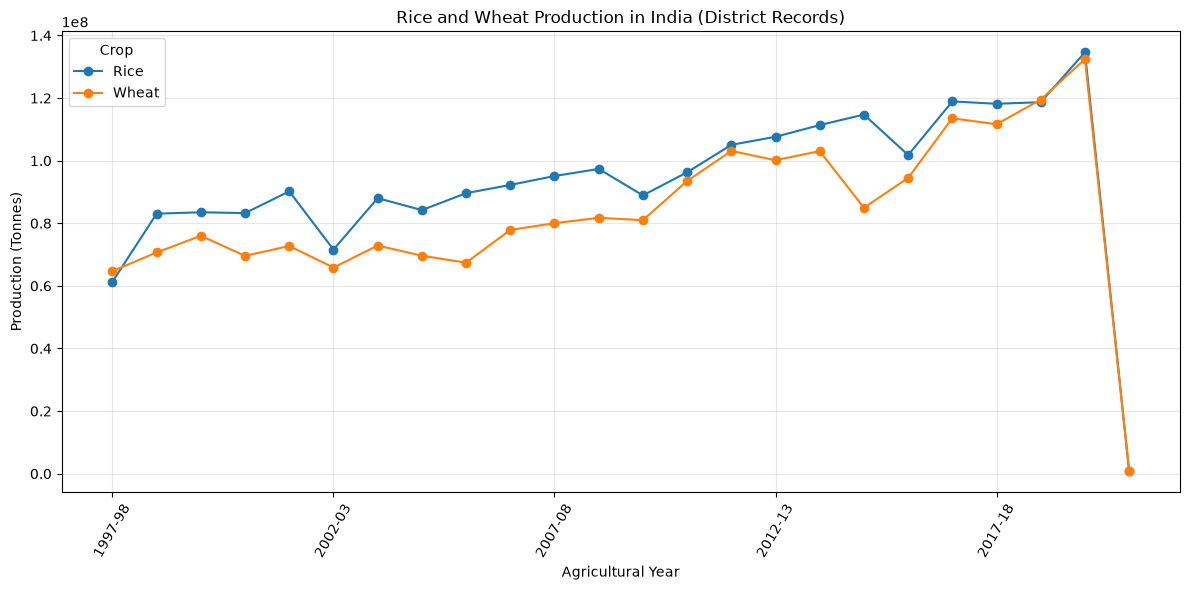

In [11]:
production_pivot = yearly_crop.pivot(
    index="Year",
    columns="Crop",
    values="Total_Production_Tonnes"
).sort_index()

ax = production_pivot.plot(
    figsize=(12, 6),
    marker="o"
)

ax.set_title("Rice and Wheat Production in India (District Records)")
ax.set_xlabel("Agricultural Year")
ax.set_ylabel("Production (Tonnes)")
ax.grid(True, alpha=0.3)

plt.xticks(rotation=60)
plt.tight_layout()

plt.savefig(
    "../images/rice_wheat_production_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

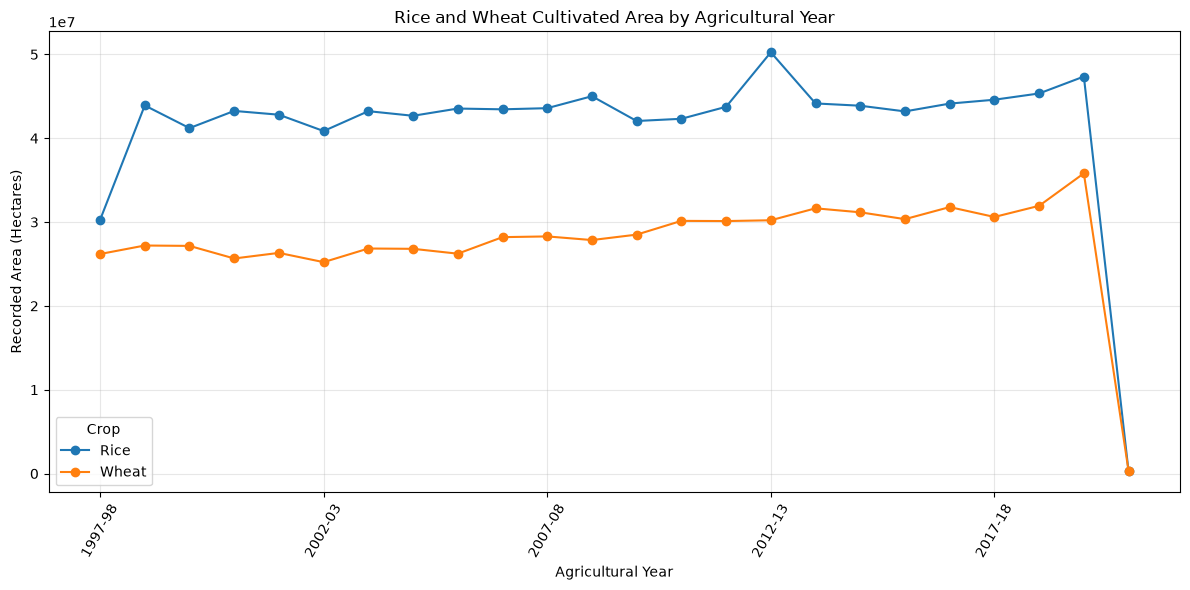

In [12]:
area_pivot = yearly_crop.pivot(
    index="Year",
    columns="Crop",
    values="Total_Area_Hectares"
).sort_index()

ax = area_pivot.plot(
    figsize=(12, 6),
    marker="o"
)

ax.set_title("Rice and Wheat Cultivated Area by Agricultural Year")
ax.set_xlabel("Agricultural Year")
ax.set_ylabel("Recorded Area (Hectares)")
ax.grid(True, alpha=0.3)

plt.xticks(rotation=60)
plt.tight_layout()

plt.savefig(
    "../images/rice_wheat_area_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
# Select Rice and Wheat
selected_crops = crops[
    crops["Crop"].isin(["Rice", "Wheat"])
].copy()

# Keep records with known area and production
crop_data = selected_crops.dropna(
    subset=["Crop", "Year", "Area", "Production"]
).copy()

# Aggregate by agricultural year and crop
yearly_crop = (
    crop_data.groupby(["Year", "Crop"], as_index=False)
    .agg(
        Total_Area_Hectares=("Area", "sum"),
        Total_Production_Tonnes=("Production", "sum"),
        Records=("Production", "count")
    )
)

# Calculate yield from aggregated area and production
yearly_crop["Calculated_Yield_Tonnes_Per_Hectare"] = (
    yearly_crop["Total_Production_Tonnes"]
    / yearly_crop["Total_Area_Hectares"].replace(0, np.nan)
)

display(yearly_crop.tail(12))

,Year,Crop,Total_Area_Hectares,Total_Production_Tonnes,Records,Calculated_Yield_Tonnes_Per_Hectare
36,2015-16,Rice,43197734.00,1.017974e+08,998,2.356545
37,2015-16,Wheat,30345389.00,9.447139e+07,513,3.113204
38,2016-17,Rice,44128759.47,1.189361e+08,1071,2.695207
39,2016-17,Wheat,31784843.00,1.135476e+08,519,3.572381
40,2017-18,Rice,44591061.75,1.181793e+08,1126,2.650291
41,2017-18,Wheat,30605607.50,1.116353e+08,523,3.647544
42,2018-19,Rice,45337851.32,1.186900e+08,1110,2.617900
43,2018-19,Wheat,31936823.65,1.195103e+08,529,3.742084
44,2019-20,Rice,47354250.12,1.346315e+08,1144,2.843071
45,2019-20,Wheat,35809575.00,1.324181e+08,519,3.697841


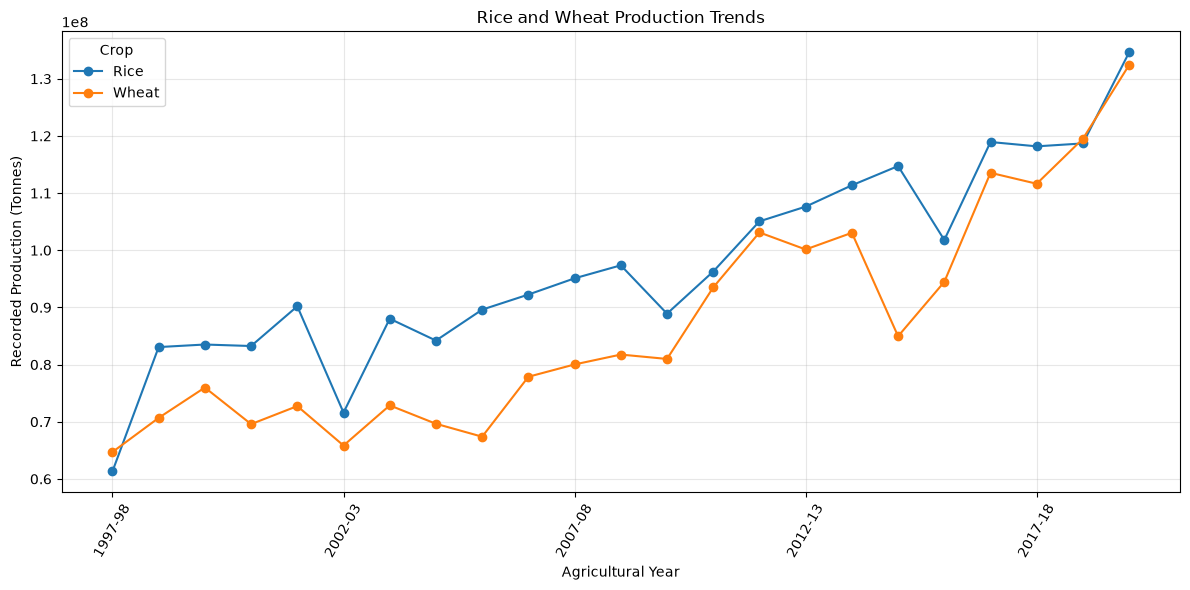

In [14]:
# Exclude the clearly incomplete 2020-21 records from this comparison
complete_years = yearly_crop[
    yearly_crop["Year"] != "2020-21"
].copy()

production_pivot = complete_years.pivot(
    index="Year",
    columns="Crop",
    values="Total_Production_Tonnes"
).sort_index()

ax = production_pivot.plot(
    figsize=(12, 6),
    marker="o"
)

ax.set_title("Rice and Wheat Production Trends")
ax.set_xlabel("Agricultural Year")
ax.set_ylabel("Recorded Production (Tonnes)")
ax.grid(True, alpha=0.3)

plt.xticks(rotation=60)
plt.tight_layout()

plt.savefig(
    "../images/rice_wheat_production_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

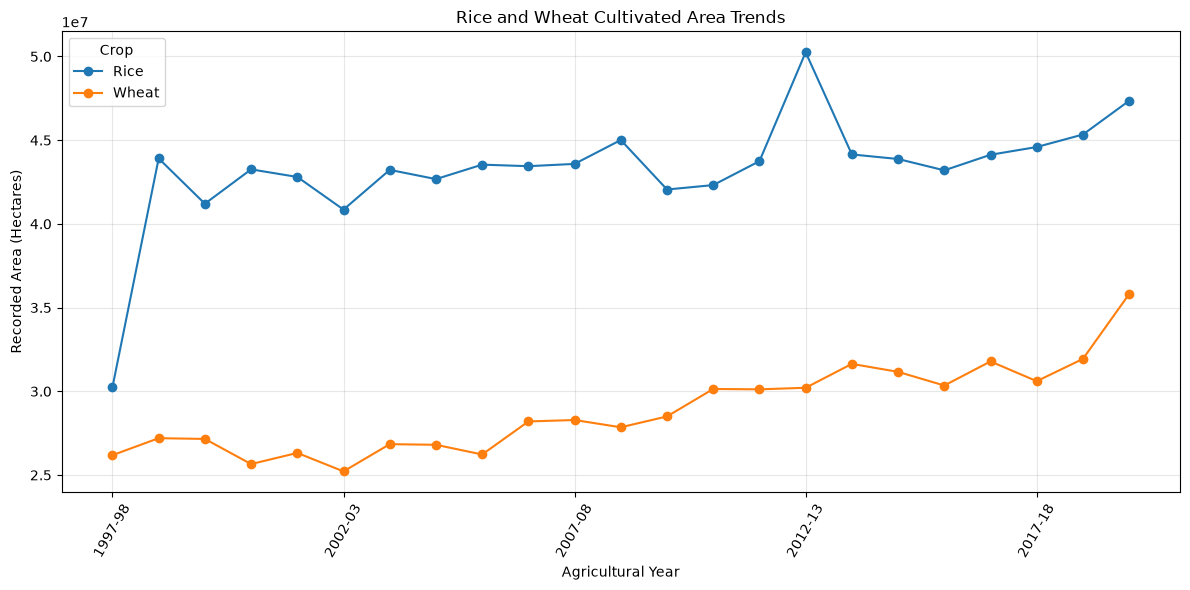

In [15]:
area_pivot = complete_years.pivot(
    index="Year",
    columns="Crop",
    values="Total_Area_Hectares"
).sort_index()

ax = area_pivot.plot(figsize=(12, 6), marker="o")

ax.set_title("Rice and Wheat Cultivated Area Trends")
ax.set_xlabel("Agricultural Year")
ax.set_ylabel("Recorded Area (Hectares)")
ax.grid(True, alpha=0.3)

plt.xticks(rotation=60)
plt.tight_layout()

plt.savefig(
    "../images/rice_wheat_area_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

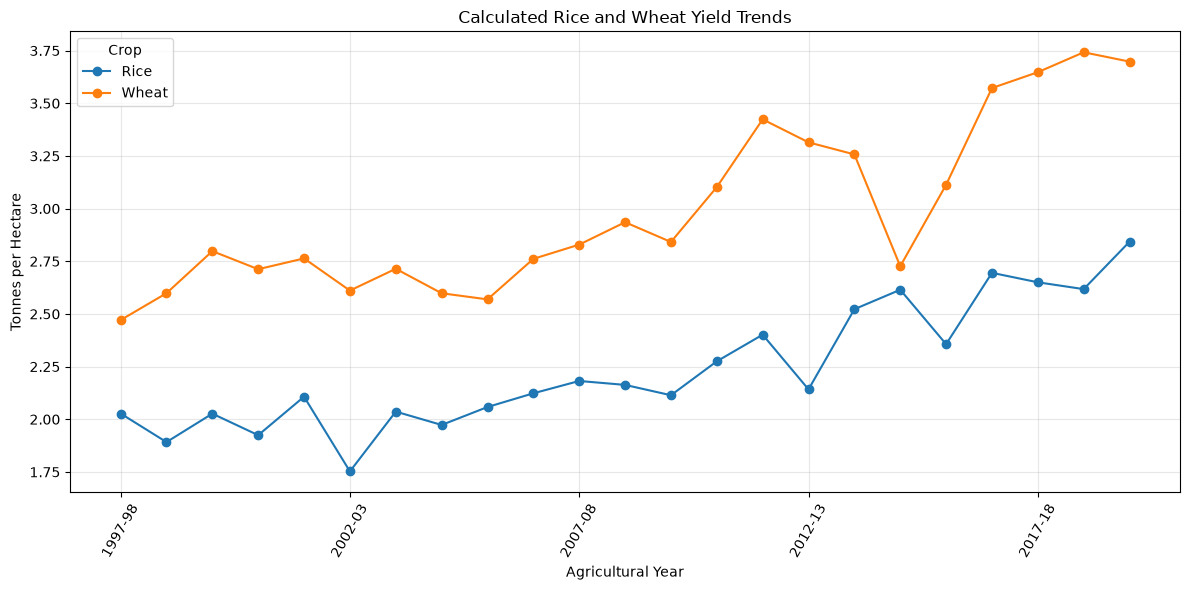

In [16]:
yield_pivot = complete_years.pivot(
    index="Year",
    columns="Crop",
    values="Calculated_Yield_Tonnes_Per_Hectare"
).sort_index()

ax = yield_pivot.plot(figsize=(12, 6), marker="o")

ax.set_title("Calculated Rice and Wheat Yield Trends")
ax.set_xlabel("Agricultural Year")
ax.set_ylabel("Tonnes per Hectare")
ax.grid(True, alpha=0.3)

plt.xticks(rotation=60)
plt.tight_layout()

plt.savefig(
    "../images/rice_wheat_yield_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
# Check Rice and Wheat records by season
display(
    selected_crops.groupby(["Crop", "Season"])
    .size()
    .unstack(fill_value=0)
)
print(
    selected_crops.groupby(["Crop", "Season"])
    .size()
    .to_string()
)

Season,Autumn,Kharif,Rabi,Summer,Whole Year,Winter
Crop,,,,,,
Rice,3099,9831,1220,4105,74,3282
Wheat,0,12,10819,326,57,33


Crop   Season    
Rice   Autumn         3099
       Kharif         9831
       Rabi           1220
       Summer         4105
       Whole Year       74
       Winter         3282
Wheat  Kharif           12
       Rabi          10819
       Summer          326
       Whole Year       57
       Winter           33


In [19]:

# Step 1: Keep Rice and Wheat records with valid area and production
crop_data = selected_crops.dropna(
    subset=["Year", "Area", "Production"]
).copy()

# Step 2: Summarize data separately for each season
season_summary = (
    crop_data.groupby(["Year", "Crop", "Season"], as_index=False)
    .agg(
        Total_Area_Hectares=("Area", "sum"),
        Total_Production_Tonnes=("Production", "sum"),
        Records=("Production", "count")
    )
)

# Step 3: Inspect the earliest year
display(
    season_summary[season_summary["Year"] == "1997-98"]
    .sort_values(["Crop", "Season"])
)

# Step 4: Inspect season-wise records for both crops
print("\nRecords per crop and season:")
print(
    crop_data.groupby(["Crop", "Season"])
    .size()
    .to_string()
)


,Year,Crop,Season,Total_Area_Hectares,Total_Production_Tonnes,Records
0,1997-98,Rice,Autumn,1780150.0,2043006.0,90
1,1997-98,Rice,Kharif,14511608.0,33337540.0,256
2,1997-98,Rice,Rabi,1178206.0,3420352.0,39
3,1997-98,Rice,Summer,1781212.0,4797275.0,148
4,1997-98,Rice,Whole Year,740714.0,1152873.0,18
5,1997-98,Rice,Winter,10251853.0,16566516.0,96
6,1997-98,Wheat,Rabi,26186026.0,64704641.0,403



Records per crop and season:
Crop   Season    
Rice   Autumn         3094
       Kharif         9816
       Rabi           1219
       Summer         4090
       Whole Year       74
       Winter         3280
Wheat  Kharif            7
       Rabi          10798
       Summer          326
       Whole Year       56
       Winter           32


In [20]:

# Select the main season for each crop
main_seasons = {
    "Rice": "Kharif",
    "Wheat": "Rabi"
}

main_crop_data = crop_data[
    crop_data.apply(
        lambda row: main_seasons.get(row["Crop"]) == row["Season"],
        axis=1
    )
].copy()

# Aggregate by year and crop
main_yearly_crop = (
    main_crop_data.groupby(["Year", "Crop"], as_index=False)
    .agg(
        Total_Area_Hectares=("Area", "sum"),
        Total_Production_Tonnes=("Production", "sum"),
        Records=("Production", "count")
    )
)

# Calculate production per hectare
main_yearly_crop["Yield_Tonnes_Per_Hectare"] = (
    main_yearly_crop["Total_Production_Tonnes"]
    / main_yearly_crop["Total_Area_Hectares"].replace(0, np.nan)
)

display(main_yearly_crop.head(10))
display(main_yearly_crop.tail(10))


,Year,Crop,Total_Area_Hectares,Total_Production_Tonnes,Records,Yield_Tonnes_Per_Hectare
0,1997-98,Rice,14511608.0,33337540.0,256,2.297302
1,1997-98,Wheat,26186026.0,64704641.0,403,2.470961
2,1998-99,Rice,24280749.0,47876569.0,375,1.971791
3,1998-99,Wheat,27195823.0,70672743.0,417,2.598662
4,1999-00,Rice,25744811.0,54909248.6,452,2.132828
5,1999-00,Wheat,27154877.0,75986522.0,415,2.798264
6,2000-01,Rice,25667788.0,51378604.8,437,2.001676
7,2000-01,Wheat,25653585.0,69583556.9,451,2.712430
8,2001-02,Rice,29219164.0,60896564.0,467,2.084131
9,2001-02,Wheat,26319464.0,72739164.9,446,2.763702


,Year,Crop,Total_Area_Hectares,Total_Production_Tonnes,Records,Yield_Tonnes_Per_Hectare
38,2016-17,Rice,25238887.00,6.861897e+07,464,2.718779
39,2016-17,Wheat,31784785.00,1.135475e+08,513,3.572385
40,2017-18,Rice,25061199.70,6.557715e+07,463,2.616680
41,2017-18,Wheat,30605381.50,1.116348e+08,510,3.647555
42,2018-19,Rice,26368046.00,6.852936e+07,474,2.598955
43,2018-19,Wheat,31936675.25,1.195100e+08,520,3.742093
44,2019-20,Rice,26996231.00,7.597322e+07,471,2.814216
45,2019-20,Wheat,35809456.00,1.324179e+08,512,3.697848
46,2020-21,Rice,241936.00,6.693720e+05,13,2.766732
47,2020-21,Wheat,297189.00,9.370030e+05,13,3.152886


In [21]:

print("Year range:", main_yearly_crop["Year"].min(),
      "to", main_yearly_crop["Year"].max())

print("\nNumber of records per crop:")
print(main_crop_data.groupby("Crop").size())

print("\nProduction units:")
print(main_crop_data.groupby(["Crop", "Production Units"]).size())

print("\nMissing values in yearly summary:")
print(main_yearly_crop.isna().sum())

print("\n2020-21 records:")
display(main_yearly_crop[main_yearly_crop["Year"] == "2020-21"])


Year range: 1997-98 to 2020-21

Number of records per crop:
Crop
Rice      9816
Wheat    10798
dtype: int64

Production units:
Crop   Production Units
Rice   Tonnes               9816
Wheat  Tonnes              10798
dtype: int64

Missing values in yearly summary:
Year                        0
Crop                        0
Total_Area_Hectares         0
Total_Production_Tonnes     0
Records                     0
Yield_Tonnes_Per_Hectare    0
dtype: int64

2020-21 records:


,Year,Crop,Total_Area_Hectares,Total_Production_Tonnes,Records,Yield_Tonnes_Per_Hectare
46,2020-21,Rice,241936.0,669372.0,13,2.766732
47,2020-21,Wheat,297189.0,937003.0,13,3.152886


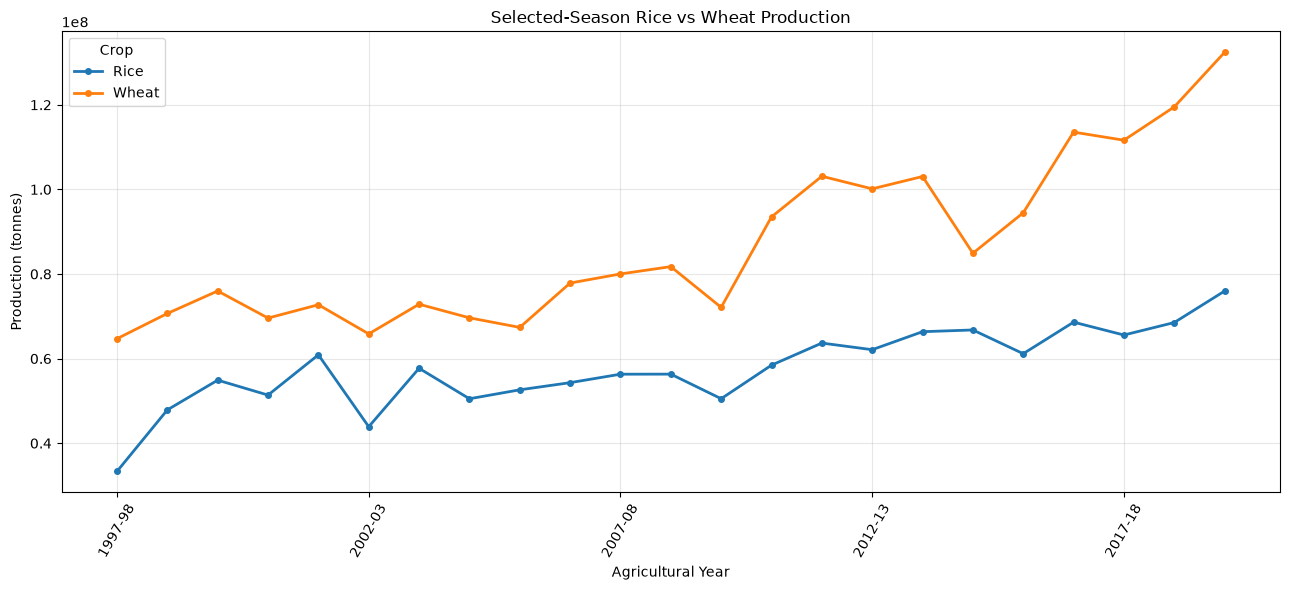

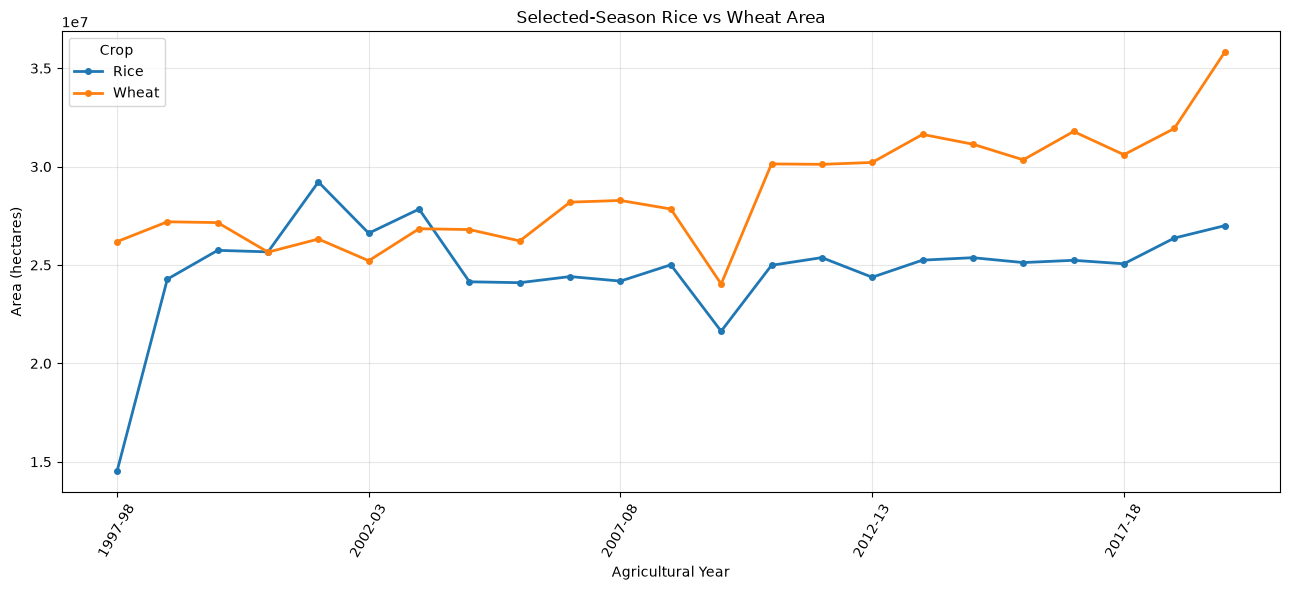

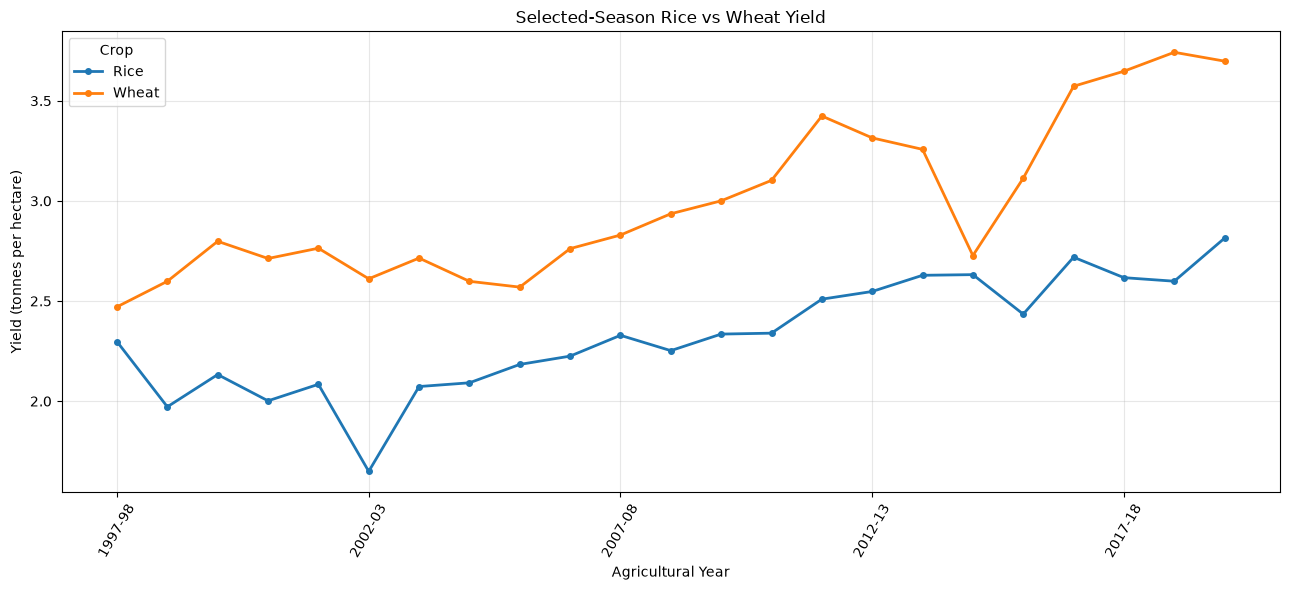

All three graphs saved successfully!


In [23]:

import matplotlib.pyplot as plt
from pathlib import Path

# Exclude incomplete 2020-21 data
trend_data = main_yearly_crop[
    main_yearly_crop["Year"] != "2020-21"
].copy()

# Ensure chronological order
trend_data = trend_data.sort_values("Year")

# Folder for saving graphs
output_dir = Path("../images")
output_dir.mkdir(parents=True, exist_ok=True)

# Metrics to visualize
metrics = [
    (
        "Total_Production_Tonnes",
        "Selected-Season Rice vs Wheat Production",
        "Production (tonnes)",
        "rice_wheat_production_trend.png"
    ),
    (
        "Total_Area_Hectares",
        "Selected-Season Rice vs Wheat Area",
        "Area (hectares)",
        "rice_wheat_area_trend.png"
    ),
    (
        "Yield_Tonnes_Per_Hectare",
        "Selected-Season Rice vs Wheat Yield",
        "Yield (tonnes per hectare)",
        "rice_wheat_yield_trend.png"
    )
]

for metric, title, ylabel, filename in metrics:
    pivot = trend_data.pivot(
        index="Year",
        columns="Crop",
        values=metric
    )

    ax = pivot.plot(
        figsize=(13, 6),
        marker="o",
        linewidth=2,
        markersize=4
    )

    ax.set_title(title)
    ax.set_xlabel("Agricultural Year")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
    plt.xticks(rotation=60)
    plt.legend(title="Crop")
    plt.tight_layout()

    plt.savefig(output_dir / filename, dpi=200)
    plt.show()
    plt.close()

print("All three graphs saved successfully!")


In [24]:

from pathlib import Path

# Output folders
processed_dir = Path("../data/processed")
images_dir = Path("../images")

processed_dir.mkdir(parents=True, exist_ok=True)
images_dir.mkdir(parents=True, exist_ok=True)

# Save selected-season yearly summary
main_yearly_crop.to_csv(
    processed_dir / "rice_wheat_selected_season_summary.csv",
    index=False
)

# Save data used for trend graphs (excludes incomplete 2020-21)
trend_data.to_csv(
    processed_dir / "rice_wheat_trend_data.csv",
    index=False
)

print("Saved files:")
print(processed_dir / "rice_wheat_selected_season_summary.csv")
print(processed_dir / "rice_wheat_trend_data.csv")


Saved files:
..\data\processed\rice_wheat_selected_season_summary.csv
..\data\processed\rice_wheat_trend_data.csv
